<a href="https://colab.research.google.com/github/4ldooo/pm-turi4-clustering/blob/main/PM_TuRi4_P9_AhmadAliMurtadlo_2488010056.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TuRi 4 - Clustering dengan K-Means
**Mata Kuliah:** Pembelajaran Mesin (INF62325) | **Pertemuan 9** | Repo: `pm-turi4-clustering`

**Nama:** Ahmad Ali Nurtadlo | **NIM:** 2488010056

**Tujuan:** menyiapkan data tanpa label (scaling), menentukan K dengan Elbow, menjalankan K-Means, mengevaluasi dengan silhouette score, dan menafsirkan cluster (segmentasi pelanggan).

## 0. Membuat Dataset Segmentasi Pelanggan (buatan)
Dataset sintetis 300 pelanggan dengan fitur `usia`, `pendapatan` (juta Rp/tahun), dan `skor_belanja` (1–100). **Tidak ada kolom label** (unsupervised).

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
def grup(n, usia, pend, skor):
    return pd.DataFrame({'usia': rng.normal(*usia, n),
                         'pendapatan': rng.normal(*pend, n),
                         'skor_belanja': rng.normal(*skor, n)})

df = pd.concat([
    grup(100, (24, 3), (35, 6), (80, 8)),    # muda, pendapatan sedang, belanja tinggi
    grup(100, (45, 5), (95, 10), (75, 8)),   # dewasa, pendapatan tinggi, belanja tinggi
    grup(100, (50, 6), (40, 8), (25, 8)),    # paruh baya, pendapatan rendah, belanja rendah
], ignore_index=True)
df['usia'] = df['usia'].clip(18, 70).round().astype(int)
df['pendapatan'] = df['pendapatan'].clip(10, None).round(1)
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round().astype(int)

print(df.shape)
df.head()

(300, 3)


,usia,pendapatan,skor_belanja
0,25,32.7,83
1,21,42.8,91
2,26,32.9,81
3,27,39.4,85
4,18,29.4,64


In [ ]:
df.describe().round(2)

,usia,pendapatan,skor_belanja
count,300.00,300.00,300.00
mean,39.57,56.60,59.14
std,12.26,28.15,26.50
min,18.00,21.80,4.00
25%,26.00,34.08,28.00
50%,44.00,43.20,71.00
75%,49.00,88.28,79.00
max,65.00,121.00,100.00


## Langkah 1 - Menyiapkan data & scaling (wajib)
K-Means berbasis jarak, jadi fitur dengan rentang besar (pendapatan) akan mendominasi jika tidak disamakan skalanya. `StandardScaler` mengubah tiap fitur menjadi rata-rata 0 dan simpangan baku 1.

In [ ]:
X_scaled = StandardScaler().fit_transform(df)
print(pd.DataFrame(X_scaled, columns=df.columns).describe().round(2).loc[['mean','std']])

      usia  pendapatan  skor_belanja
mean   0.0         0.0           0.0
std    1.0         1.0           1.0


## Langkah 2 - Metode Elbow untuk menentukan K

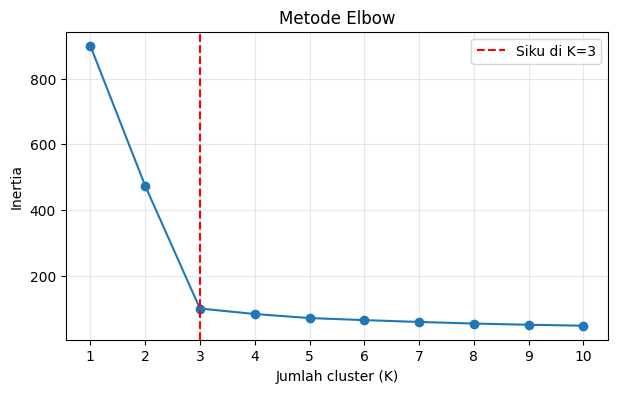

K= 1  inertia=   900.0
K= 2  inertia=   474.0
K= 3  inertia=    99.8
K= 4  inertia=    83.0
K= 5  inertia=    70.7
K= 6  inertia=    64.4
K= 7  inertia=    58.8
K= 8  inertia=    54.0
K= 9  inertia=    50.3
K=10  inertia=    47.4


In [ ]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1,11), inertias, marker='o')
plt.axvline(3, color='red', linestyle='--', label='Siku di K=3')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia'); plt.title('Metode Elbow')
plt.xticks(range(1,11)); plt.legend(); plt.grid(alpha=.3); plt.show()
for k, v in zip(range(1,11), inertias): print(f'K={k:2d}  inertia={v:8.1f}')

**Pembacaan grafik:** inertia turun tajam dari K=1 → K=2 → K=3 (900 → 474 → ≈100), kemudian penurunannya melandai (K=4 ≈ 83, K=5 ≈ 71, dst.). Titik “siku” berada di **K=3**, sehingga K=3 dipilih.

## Langkah 3 - Menjalankan K-Means (K=3)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0    100
1    100
2    100
Name: count, dtype: int64


## Langkah 4 - Evaluasi silhouette score

In [ ]:
from sklearn.metrics import silhouette_score
sil_k3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette score (K=3):', round(sil_k3, 4))

Silhouette score (K=3): 0.7285


Silhouette berkisar −1 s.d. 1; semakin mendekati 1 berarti cluster padat dan terpisah baik. Nilai ≈ 0,73 tergolong **sangat baik** (> 0,7 = struktur cluster kuat).

## Langkah 5 - Interpretasi: profil rata-rata tiap cluster

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        45.5        94.6          74.3
1        49.4        40.3          23.7
2        23.8        34.9          79.5


In [ ]:
# Penamaan cluster berdasarkan profil (aturan dibuat agar tidak bergantung pada nomor cluster)
nama = {}
nama[profil['pendapatan'].idxmax()]   = 'Pelanggan Premium (Mapan & Loyal)'
nama[profil['usia'].idxmin()]         = 'Pelanggan Muda Konsumtif'
nama[profil['skor_belanja'].idxmin()] = 'Pelanggan Hemat (Pasif)'
df['segmen'] = df['cluster'].map(nama)
print(nama)
print(df.groupby('segmen')[['usia','pendapatan','skor_belanja']].agg(['mean']).round(1))

{np.int32(0): 'Pelanggan Premium (Mapan & Loyal)', np.int32(2): 'Pelanggan Muda Konsumtif', np.int32(1): 'Pelanggan Hemat (Pasif)'}
                                   usia pendapatan skor_belanja
                                   mean       mean         mean
segmen                                                         
Pelanggan Hemat (Pasif)            49.4       40.3         23.7
Pelanggan Muda Konsumtif           23.8       34.9         79.5
Pelanggan Premium (Mapan & Loyal)  45.5       94.6         74.3


**Interpretasi segmen:**

| Segmen | Profil | Strategi yang disarankan |
|---|---|---|
| **Pelanggan Muda Konsumtif** | Usia ≈ 24 th, pendapatan sedang (≈ 35 jt), skor belanja tinggi (≈ 80) | Promo digital, diskon musiman, program *cashback*/media sosial |
| **Pelanggan Premium (Mapan & Loyal)** | Usia ≈ 45 th, pendapatan tinggi (≈ 95 jt), skor belanja tinggi (≈ 75) | Program loyalitas VIP, produk eksklusif, layanan prioritas |
| **Pelanggan Hemat (Pasif)** | Usia ≈ 49 th, pendapatan rendah (≈ 40 jt), skor belanja rendah (≈ 24) | Penawaran harga terjangkau, bundling, kampanye reaktivasi |

---
## D. Latihan Mandiri

### Latihan 1: K-Means K=5 vs K=3

In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
lab5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, lab5)
print(f'Silhouette K=3: {sil_k3:.4f}')
print(f'Silhouette K=5: {sil_k5:.4f}')

Silhouette K=3: 0.7285
Silhouette K=5: 0.4662


**Kesimpulan:** silhouette K=5 (≈ 0,47) **lebih rendah** daripada K=3 (≈ 0,73). Karena data sebenarnya terdiri dari 3 kelompok alami, K=5 memecah kelompok yang utuh menjadi bagian-bagian yang saling berdekatan sehingga batas antar-cluster kabur. K=3 adalah pilihan terbaik.

### Latihan 2: K-Means tanpa scaling (K=3)

In [ ]:
X_raw = df[['usia','pendapatan','skor_belanja']]
lab_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_raw)
sil_raw = silhouette_score(X_raw, lab_raw)
print(f'Silhouette DENGAN scaling : {sil_k3:.4f}')
print(f'Silhouette TANPA scaling  : {sil_raw:.4f}')

# seberapa mirip pengelompokan tanpa scaling dengan scaling?
from sklearn.metrics import adjusted_rand_score
print('Kemiripan pengelompokan (ARI):', round(adjusted_rand_score(df['cluster'], lab_raw), 4))

# fitur mana yang dominan? lihat rentang tiap fitur
print(X_raw.agg(['min','max','std']).round(1))

Silhouette DENGAN scaling : 0.7285
Silhouette TANPA scaling  : 0.7419
Kemiripan pengelompokan (ARI): 1.0
     usia  pendapatan  skor_belanja
min  18.0        21.8           4.0
max  65.0       121.0         100.0
std  12.3        28.1          26.5


**Kesimpulan:**
- Pada dataset ini nilai silhouette tanpa scaling (≈ 0,74) hampir sama, bahkan sedikit lebih tinggi daripada dengan scaling (≈ 0,73). Itu **bukan** berarti scaling tidak perlu: silhouette dihitung di ruang fitur yang berbeda (mentah vs. terstandar), sehingga angkanya tidak bisa dibandingkan secara adil.
- Penyebab: tanpa scaling, jarak didominasi fitur berskala besar (`pendapatan`, simpangan baku ≈ 28) sedangkan `usia` (≈ 12) dan `skor_belanja` (≈ 26) kontribusinya lebih kecil. Pada data ini ketiga kelompok kebetulan sangat terpisah pada pendapatan, sehingga hasilnya masih mirip (ARI = 1,0: pengelompokan identik).
- Pada data nyata (mis. pendapatan dalam rupiah penuh, ratusan juta, berdampingan dengan usia 20–60), fitur berskala besar akan **mendominasi seluruh jarak** dan cluster hanya mencerminkan satu fitur. Karena itu scaling tetap **wajib** pada K-Means.

### Latihan 3: Scatter plot cluster: usia (x) vs skor_belanja (y)

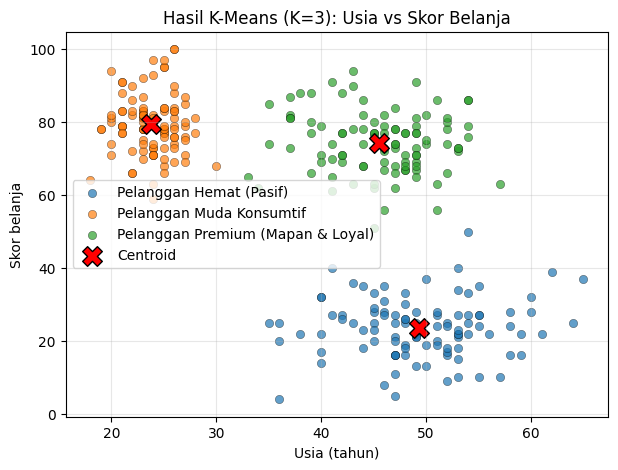

In [ ]:
plt.figure(figsize=(7,5))
for seg, g in df.groupby('segmen'):
    plt.scatter(g['usia'], g['skor_belanja'], label=seg, alpha=.7, edgecolor='k', linewidth=.3)

# centroid dikembalikan ke skala asli
cent = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
plt.scatter(cent[:,0], cent[:,2], c='red', marker='X', s=200, edgecolor='k', label='Centroid')
plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja'); plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Catatan:** pada sumbu usia–skor belanja, segmen *Muda Konsumtif* terpisah jelas (usia rendah, skor tinggi) dan *Hemat* berada di skor rendah. Segmen *Premium* dan *Muda* dibedakan oleh usia, tetapi *Premium* tampak dekat dengan *Hemat* pada usia; pemisahnya adalah pendapatan yang tidak tampak di plot 2D ini.


## E. Refleksi

### 1. Bagaimana K-Means menemukan kelompok tanpa label?

Menurut saya, K-Means bekerja dengan cara mengelompokkan data berdasarkan kemiripan jarak antar-data. Algoritma ini menentukan beberapa titik pusat (*centroid*), kemudian memasukkan setiap data ke kelompok dengan centroid yang paling dekat. Setelah itu, posisi centroid diperbarui berdasarkan rata-rata data di dalam kelompok tersebut. Proses ini terus diulang sampai posisi centroid tidak banyak berubah lagi. Jadi, K-Means bisa membentuk kelompok tanpa membutuhkan label sejak awal. Setelah kelompok terbentuk, kita bisa melihat karakteristik masing-masing kelompok untuk memahami perbedaannya.

### 2. Mengapa Elbow menunjukkan siku di K=3 pada data ini?

Berdasarkan hasil percobaan, titik siku pada grafik Elbow terlihat di K=3 karena data yang digunakan memiliki tiga kelompok alami. Ketika jumlah cluster ditambah dari K=1 sampai K=3, nilai inertia mengalami penurunan yang cukup besar. Hal ini menunjukkan bahwa pembagian kelompok menjadi lebih baik. Namun, setelah K=3, penurunan inertia mulai lebih kecil karena penambahan cluster hanya membagi kelompok yang sudah terbentuk menjadi bagian yang lebih kecil. Hasil ini juga didukung oleh nilai *silhouette score* tertinggi, yaitu sekitar 0,73 pada K=3. Oleh karena itu, tiga cluster menjadi pilihan yang paling sesuai untuk data ini.

### 3. Mengapa scaling penting, dan apa dampaknya jika tidak dilakukan?

Menurut saya, scaling penting karena setiap fitur dalam data bisa memiliki rentang nilai yang berbeda. K-Means menggunakan jarak untuk menentukan kelompok, sehingga fitur dengan nilai yang lebih besar bisa lebih berpengaruh dibandingkan fitur lainnya. Contohnya, fitur `pendapatan` dapat mendominasi perhitungan jarak jika nilainya jauh lebih besar daripada `usia` atau `skor_belanja`. Akibatnya, hasil pengelompokan bisa kurang seimbang dan tidak menggambarkan pola data dengan baik. Dengan melakukan scaling, rentang nilai setiap fitur menjadi lebih sebanding sehingga proses pengelompokan dapat mempertimbangkan semua fitur secara lebih proporsional.

## Kesimpulan
- Data disiapkan dengan `StandardScaler`; Elbow dan silhouette sama-sama menunjuk **K=3**.
- K-Means (K=3) menghasilkan 3 segmen dengan silhouette ≈ **0,73** (struktur cluster kuat): *Muda Konsumtif*, *Premium*, dan *Hemat*.
- K=5 menurunkan kualitas (silhouette ≈ 0,47); scaling tetap wajib walau pada data ini angka silhouette tanpa scaling kebetulan mirip.
- Hasil dapat dimanfaatkan untuk strategi pemasaran tiap segmen.